# Sample figure: seasonal SST-index ACC for one initialization month

A single-panel, presentation-style version of the seasonal ACC panel in `3a_sst_skill_ts.ipynb`
(e.g. Niño3.4, May initialization, 1980-2018). It compares E3SMv3-FOSIRL, E3SMv3-Reanalysis,
CESM2-SMYLE, the NMME multi-model mean, and the NMME single-model range. Optional shading behind the
E3SM and CESM-SMYLE lines shows the 5-95% range of ensemble-mean ACC when ensemble members are
bootstrapped (resampled with replacement), i.e. the uncertainty from finite ensemble size.

This notebook only *reads* the compact regional SST-index time series that `3a_sst_skill_ts.ipynb`
(or `scripts/run_process_sst_index.py` / `scripts/run_process_nmme_sst_index.py`) already wrote under
`s2d_diag`. It computes skill in memory with the same `esp_lab` routines (lead-dependent drift removal,
initialization-year cohort, optional detrending, HadISST2 reference) and writes nothing back to the
diagnostic caches. The figure is saved under `<FIGURE_ROOT>/sample_figures/`.

NMME cohort options:
- `"available"` (default): each NMME model is scored on the years it covers inside the verification
  window (at least `nmme_min_years`); the multi-model mean averages the models present in each year.
- `"common"`: the strict fixed cohort used by `3a_sst_skill_ts.ipynb` (only models covering every year).


In [1]:
%matplotlib inline

from pathlib import Path

import numpy as np
import pandas as pd
import xarray as xr
import matplotlib.pyplot as plt
from matplotlib.patches import Patch

from esp_lab import env_paths
from esp_lab import index_reference_skill
from esp_lab import stats
from esp_lab.utils.filename_utils import figure_filename, resolve_year_span_path, sst_index_filename
from esp_lab.utils.netcdf_utils import load_netcdf


In [2]:
# =============================================================================
# CONFIGURATION BLOCK: Edit settings here
# =============================================================================
INDEX = "Nino3.4"            # any regional index with cached products, e.g. Nino3, Nino4, IOD, TNA
INIT_MONTH = 5               # initialization month (5 = May, 11 = November)
VERIFICATION_YEARS = (1980, 2018)
CLIMATOLOGY_YEARS = (1981, 2010)
DETREND = True

E3SM_FIELD = "TS"
SMYLE_FIELD = "TS"
NLEAD = 24

# Cases drawn on the figure, in plotting order: (cache folder, label, color, linestyle, marker, ensemble size)
MODELS = [
    ("JRA55_FOSIRL", "E3SMv3-FOSIRL",     "black",      "-",  "o", 10),
    ("Reanalysis",   "E3SMv3-Reanalysis", "tab:blue",   "-",  "o", 10),
    ("CESM-SMYLE",   "CESM2-SMYLE",       "tab:orange", "--", "s", 20),
]

NMME_ON = True
NMME_ARCHIVE_PERIOD = (1980, 2020)
NMME_COHORT = "available"    # "available" or "common" (see notes above)
NMME_MIN_YEARS = 25
NMME_LABEL = "NMME ensemble mean"
NMME_RANGE_LABEL = "NMME model range"
NMME_COLOR = "red"
NMME_RANGE_COLOR = "lightcoral"

# Ensemble-member bootstrap range for the E3SM and CESM-SMYLE lines: members are drawn with
# replacement, the ensemble-mean ACC recomputed, and the percentile range shaded behind each line.
SHOW_MODEL_UNCERTAINTY = True
UNCERTAINTY_ITERATIONS = 1000
UNCERTAINTY_PERCENTILES = (5, 95)
UNCERTAINTY_ENS_SIZE = None   # None = each model's own ensemble size; e.g. 10 to match all models
UNCERTAINTY_SEED = 0

# Figure options
HIGHLIGHT_SPB = True         # outline the spring predictability barrier (May initialization)
ACC_YLIM = (0.0, 1.0)
ACC_HLINE = 0.5
FIGSIZE = (11.0, 6.5)
DPI = 600
FIGFMT = "png"

REGIONS_COORDS = {
    "Nino12":      [270.0, 280.0, -10.0,  0.0],
    "Nino3":       [210.0, 270.0,  -5.0,  5.0],
    "Nino3.4":     [190.0, 240.0,  -5.0,  5.0],
    "Nino4":       [160.0, 210.0,  -5.0,  5.0],
    "TNA":         [305.0, 345.0,   5.0, 25.0],
    "TSA":         [330.0,  10.0, -20.0,  0.0],
    "PACWRAMPOOL": [ 60.0, 170.0, -15.0, 15.0],
    "AtlNino":     [340.0, 360.0,  -3.0,  3.0],
    "AtlMDR":      [280.0, 350.0,  10.0, 20.0],
    "IOD":         [ 50.0, 110.0, -10.0, 10.0],
    "TNI":         [160.0, 280.0, -10.0, 10.0],
    "ONI":         [190.0, 240.0,  -5.0,  5.0],
    "RONI":        [190.0, 240.0, -20.0, 20.0],
}

S2D_DIAG_ROOT = env_paths.s2d_diag_root()
OBS_SST_DIR = S2D_DIAG_ROOT / "observations" / "sst_index" / "timeseries"
NMME_SST_DIR = S2D_DIAG_ROOT / "NMME" / "sst_index" / "timeseries"
FIGURE_OUTDIR = env_paths.figure_root() / "sample_figures"
FIGURE_OUTDIR.mkdir(parents=True, exist_ok=True)
# ===== END CONFIGURATION BLOCK =====

skill_year0, skill_year1 = VERIFICATION_YEARS
climy0, climy1 = CLIMATOLOGY_YEARS
if NMME_COHORT not in {"available", "common"}:
    raise ValueError("NMME_COHORT must be 'available' or 'common'")
print(f"S2D_DIAG_ROOT: {S2D_DIAG_ROOT}")
print(f"FIGURE_OUTDIR: {FIGURE_OUTDIR}")


S2D_DIAG_ROOT: /global/cfs/cdirs/e3sm/S2S2D/s2d_diag
FIGURE_OUTDIR: /global/cfs/cdirs/e3sm/www/zhan391/e3sm-s2d_diag/sample_figures


In [3]:
# -----------------------------
# Load cached SST-index series and compute seasonal ACC against HadISST2
# -----------------------------
obs_seas = load_netcdf(OBS_SST_DIR / f"HadISST2_sst_{INDEX}SST_seas.nc")["sst"]
references = {"HadISST2": (obs_seas, False)}


def model_seasonal_skill(source, field, nens):
    """Drift-corrected seasonal skill of one hindcast set, as in 3a_sst_skill_ts.ipynb."""
    path = resolve_year_span_path(
        S2D_DIAG_ROOT / source / "sst_index" / "timeseries"
        / sst_index_filename(source, INIT_MONTH, VERIFICATION_YEARS, nens, NLEAD,
                             index=INDEX, field=field, seasonal=True)
    )
    if not path.is_file():
        raise FileNotFoundError(f"Missing {source} SST-index series {path}; run 3a_sst_skill_ts.ipynb first.")
    ds = load_netcdf(path)
    data, time, _ = index_reference_skill.retain_complete_seasonal_leads(
        ds["sst"], ds["time"], label=source, expected_count=NLEAD // 3 - 1
    )
    data_dd, _ = stats.remove_drift(data, time, climy0, climy1)
    data_dd, time = index_reference_skill.subset_hindcast_initialization_years(
        data_dd, time, skill_year0, skill_year1
    )
    skill = index_reference_skill.compute_reference_skill(
        data_dd, time, references, climy0, climy1, detrend=DETREND, monthly=False
    ).sel(reference="HadISST2")
    print(f"{source}: {path.name}")
    return skill, data_dd, time


def member_bootstrap_range(data_dd, time, rng):
    """Percentile range of ensemble-mean ACC over members resampled with replacement."""
    nmem = data_dd.sizes["M"]
    ens_size = nmem if UNCERTAINTY_ENS_SIZE is None else int(UNCERTAINTY_ENS_SIZE)
    member_indices = rng.integers(0, nmem, size=(UNCERTAINTY_ITERATIONS, ens_size))
    corr = stats.compute_skill_seasonal_batch(
        data_dd, time, obs_seas, climy0, climy1, member_indices_all=member_indices,
        nleads=data_dd.sizes["L"], detrend=DETREND, metrics=("corr",),
    )["corr"].load()
    return corr.quantile([q / 100 for q in UNCERTAINTY_PERCENTILES], dim="iteration")


def nmme_seasonal_skill():
    """Return (multi-model-mean skill, per-model skill) for the selected NMME cohort."""
    path = NMME_SST_DIR / (
        f"NMME_init{INIT_MONTH:02d}_{INDEX.replace('.', '')}SST_seas_dd_"
        f"{NMME_ARCHIVE_PERIOD[0]}_{NMME_ARCHIVE_PERIOD[1]}.nc"
    )
    if not path.is_file():
        raise FileNotFoundError(f"Missing NMME SST-index series {path}; run 3a_sst_skill_ts.ipynb first.")
    ds = load_netcdf(path)
    data, time = index_reference_skill.subset_hindcast_initialization_years(
        ds["sst"], ds["time"], skill_year0, skill_year1
    )
    data, time, _ = index_reference_skill.retain_complete_seasonal_leads(data, time, label="NMME")
    nleads = data.sizes["L"]
    covered = data.mean("M").notnull().all("L")       # (model, Y): year scored for every lead

    if NMME_COHORT == "common":
        keep = covered.all("Y")
    else:
        keep = covered.sum("Y") >= NMME_MIN_YEARS
    models = [str(m) for m in data.model.values[keep.values]]
    if not models:
        raise ValueError(f"No NMME models satisfy NMME_COHORT={NMME_COHORT!r}")

    per_model = []
    for model in models:
        years_ok = covered.sel(model=model).values
        per_model.append(stats.compute_skill_seasonal(
            data.sel(model=model, Y=data.Y[years_ok]).dropna("M", how="all"),
            time.sel(Y=time.Y[years_ok]),
            obs_seas, climy0, climy1, nleads=nleads, detrend=DETREND,
        ))
    per_model = xr.concat(per_model, dim=xr.DataArray(models, dims="model", name="model"))

    ens_mean = data.sel(model=models).mean("M").mean("model", skipna=True).expand_dims(M=[0])
    mmm = stats.compute_skill_seasonal(ens_mean, time, obs_seas, climy0, climy1, nleads=nleads, detrend=DETREND)
    years_used = per_model["sample_count"].max("L").astype(int).to_series()
    print(f"NMME ({NMME_COHORT} cohort): {len(models)} models")
    print(years_used.to_string())
    return mmm, per_model


skill_by_model = {}
acc_range_by_model = {}
rng = np.random.default_rng(UNCERTAINTY_SEED)
for source, label, *_style, nens in MODELS:
    field = SMYLE_FIELD if source == "CESM-SMYLE" else E3SM_FIELD
    skill_by_model[label], data_dd, time = model_seasonal_skill(source, field, nens)
    if SHOW_MODEL_UNCERTAINTY:
        acc_range_by_model[label] = member_bootstrap_range(data_dd, time, rng)
if NMME_ON:
    nmme_mmm_skill, nmme_model_skill = nmme_seasonal_skill()


JRA55_FOSIRL: JRA55_FOSIRL_init05_TS_y1980-2018_N10_M24_Nino3.4SST_seas.nc


Reanalysis: Reanalysis_init05_TS_y1980-2018_N10_M24_Nino3.4SST_seas.nc


CESM-SMYLE: CESM-SMYLE_init05_TS_y1980-2018_N20_M24_Nino3.4SST_seas.nc


NMME (available cohort): 17 models
model
CMC1-CanCM3            30
CMC2-CanCM4            30
COLA-RSMAS-CCSM3       37
COLA-RSMAS-CCSM4       37
COLA-RSMAS-CESM1       37
CanCM4i                38
CanSIPS-IC3            39
CanSIPS-IC4            29
CanSIPSv2              38
GEM-NEMO               38
GFDL-CM2p1             30
GFDL-CM2p1-aer04       37
GFDL-CM2p5-FLOR-A06    39
GFDL-CM2p5-FLOR-B01    39
GFDL-SPEAR             28
NCAR-CESM1             31
NCEP-CFSv2             29


In [4]:
# -----------------------------
# Seasonal ACC table (rows: lead month of the centered season)
# -----------------------------
def season_label(lead):
    """Three-letter season centered on the verification month of seasonal lead ``lead``."""
    center = (INIT_MONTH - 1 + int(lead) - 1) % 12
    return "".join("JFMAMJJASOND"[(center + k) % 12] for k in (-1, 0, 1))


acc_table = pd.DataFrame({label: skill["corr"].to_series() for label, skill in skill_by_model.items()})
for label, acc_range in acc_range_by_model.items():
    lo, hi = UNCERTAINTY_PERCENTILES
    acc_table[f"{label} p{lo}"] = acc_range.isel(quantile=0).to_series()
    acc_table[f"{label} p{hi}"] = acc_range.isel(quantile=1).to_series()
if NMME_ON:
    acc_table[NMME_LABEL] = nmme_mmm_skill["corr"].to_series()
    acc_table["NMME min"] = nmme_model_skill["corr"].min("model").to_series()
    acc_table["NMME max"] = nmme_model_skill["corr"].max("model").to_series()
acc_table.index = [f"{int(L) - 2}:{season_label(L)}" for L in acc_table.index]
acc_table.round(3)


,E3SMv3-FOSIRL,E3SMv3-Reanalysis,CESM2-SMYLE,E3SMv3-FOSIRL p5,E3SMv3-FOSIRL p95,E3SMv3-Reanalysis p5,E3SMv3-Reanalysis p95,CESM2-SMYLE p5,CESM2-SMYLE p95,NMME ensemble mean,NMME min,NMME max
1:JJA,0.846,0.847,0.788,0.820,0.861,0.827,0.860,0.775,0.797,0.851,0.696,0.873
4:SON,0.818,0.806,0.718,0.782,0.828,0.774,0.821,0.691,0.738,0.836,0.639,0.865
7:DJF,0.811,0.797,0.721,0.766,0.819,0.768,0.809,0.688,0.744,0.837,0.573,0.888
10:MAM,0.640,0.610,0.614,0.561,0.654,0.549,0.639,0.548,0.646,NaN,NaN,NaN
13:JJA,0.535,0.510,0.468,0.456,0.563,0.402,0.559,0.402,0.506,NaN,NaN,NaN
16:SON,0.503,0.629,0.483,0.424,0.534,0.509,0.670,0.410,0.525,NaN,NaN,NaN
19:DJF,0.492,0.656,0.488,0.406,0.533,0.522,0.703,0.402,0.540,NaN,NaN,NaN


Saved figure: /global/cfs/cdirs/e3sm/www/zhan391/e3sm-s2d_diag/sample_figures/fig_sst_index_nino3_4_init05_acc_sample_1980_2018.png


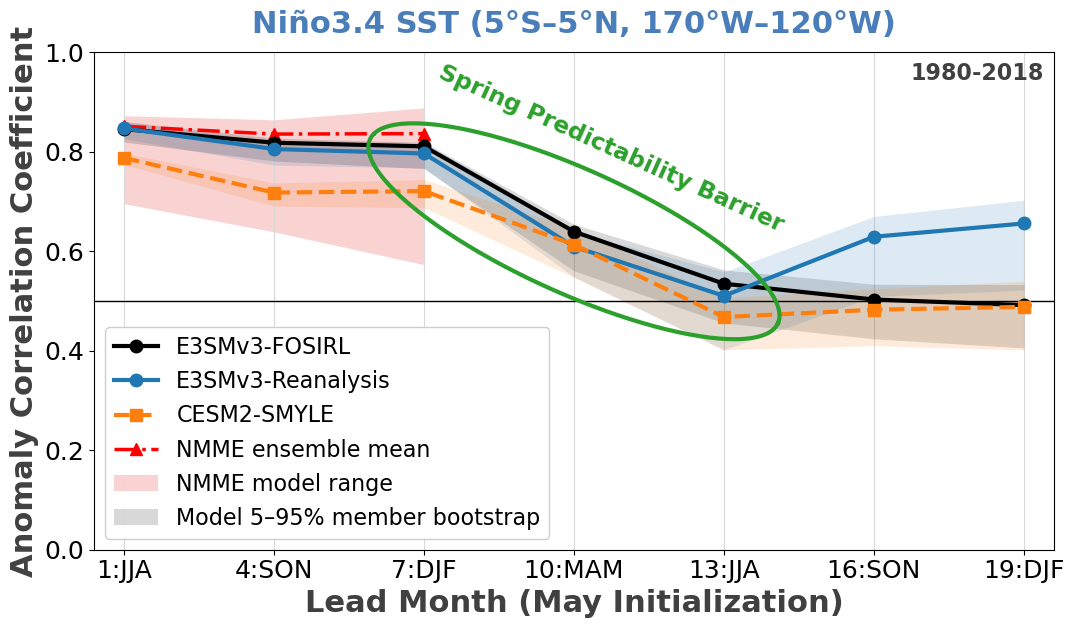

In [5]:
# -----------------------------
# Plot the single-panel ACC figure
# -----------------------------
def format_lon(lon):
    lon = (lon + 180.0) % 360.0 - 180.0
    return f"{abs(lon):g}°{'W' if lon < 0 else 'E' if lon > 0 else ''}"


def format_lat(lat):
    return f"{abs(lat):g}°{'S' if lat < 0 else 'N' if lat > 0 else ''}"


lon0, lon1, lat0, lat1 = REGIONS_COORDS[INDEX]
title = f"{INDEX.replace('Nino', 'Niño')} SST ({format_lat(lat0)}–{format_lat(lat1)}, {format_lon(lon0)}–{format_lon(lon1)})"
init_name = pd.Timestamp(2000, INIT_MONTH, 1).strftime("%B")
lead_offset = 2  # seasonal lead L is the centered month; plot lead = first month of the season

plt.rcParams.update({"font.size": 14})
fig, ax = plt.subplots(figsize=FIGSIZE)

if NMME_ON:
    plot_lead = nmme_model_skill.L - lead_offset
    ax.fill_between(plot_lead, nmme_model_skill["corr"].min("model"), nmme_model_skill["corr"].max("model"),
                    color=NMME_RANGE_COLOR, alpha=0.35, linewidth=0, label=NMME_RANGE_LABEL)
    ax.plot(nmme_mmm_skill.L - lead_offset, nmme_mmm_skill["corr"], color=NMME_COLOR, linestyle="-.",
            linewidth=2.5, marker="^", markersize=8, label=NMME_LABEL, zorder=3)

for source, label, color, linestyle, marker, _nens in MODELS:
    if label in acc_range_by_model:
        acc_range = acc_range_by_model[label]
        ax.fill_between(acc_range.L - lead_offset, acc_range.isel(quantile=0), acc_range.isel(quantile=1),
                        color=color, alpha=0.15, linewidth=0, zorder=2)

for source, label, color, linestyle, marker, _nens in MODELS:
    skill = skill_by_model[label]
    ax.plot(skill.L - lead_offset, skill["corr"], color=color, linestyle=linestyle, linewidth=3,
            marker=marker, markersize=9, label=label, zorder=4)

leads = next(iter(skill_by_model.values())).L.values
ax.set_xticks(leads - lead_offset)
ax.set_xticklabels([f"{L - lead_offset}:{season_label(L)}" for L in leads])
ax.set_xlim(leads[0] - lead_offset - 0.6, leads[-1] - lead_offset + 0.6)
ax.set_ylim(ACC_YLIM)
ax.tick_params(axis="both", labelsize=18)
ax.axhline(ACC_HLINE, color="black", linewidth=1)
ax.grid(axis="x", color="0.85")
ax.set_xlabel(f"Lead Month ({init_name} Initialization)", fontsize=22, fontweight="bold", color="0.25")
ax.set_ylabel("Anomaly Correlation Coefficient", fontsize=22, fontweight="bold", color="0.25")
ax.set_title(title, fontsize=22, fontweight="bold", color="#4a7ebb", pad=14)
ax.text(0.99, 0.98, f"{skill_year0}-{skill_year1}", transform=ax.transAxes, ha="right", va="top",
        fontsize=16, fontweight="bold", color="0.25")

# Legend order follows the sample slide: E3SM cases, CESM2-SMYLE, then NMME mean and range.
handles, labels = ax.get_legend_handles_labels()
order = [m[1] for m in MODELS] + ([NMME_LABEL, NMME_RANGE_LABEL] if NMME_ON else [])
handle_by_label = dict(zip(labels, handles))
if acc_range_by_model:
    uncertainty_label = f"Model {UNCERTAINTY_PERCENTILES[0]}–{UNCERTAINTY_PERCENTILES[1]}% member bootstrap"
    handle_by_label[uncertainty_label] = Patch(facecolor="0.5", alpha=0.3, linewidth=0)
    order.append(uncertainty_label)
ax.legend([handle_by_label[label] for label in order], order, loc="lower left",
          ncol=1, frameon=True, facecolor="white", edgecolor="0.8", framealpha=0.95, fontsize=16)
fig.tight_layout()

if HIGHLIGHT_SPB and INIT_MONTH == 5:
    # A May start meets boreal spring (MAM) of the following year between its DJF (lead 7)
    # and JJA (lead 13) targets, where skill drops sharply. Outline that segment with an
    # ellipse tilted along the multi-model mean decline, built in inches so it stays a true
    # ellipse whatever the axis scaling.
    spb_leads = (9, 15)  # seasonal L of the 7:DJF and 13:JJA targets
    spb_y = [float(np.mean([skill_by_model[m[1]]["corr"].sel(L=L) for m in MODELS])) for L in spb_leads]
    spb_x = [L - lead_offset for L in spb_leads]
    (x0, x1), (y0, y1) = ax.get_xlim(), ax.get_ylim()
    bbox = ax.get_window_extent().transformed(fig.dpi_scale_trans.inverted())
    to_in = np.array([bbox.width / (x1 - x0), bbox.height / (y1 - y0)])
    p0 = np.array([spb_x[0], spb_y[0]]) * to_in
    p1 = np.array([spb_x[1], spb_y[1]]) * to_in
    center, along = (p0 + p1) / 2, (p1 - p0) / np.linalg.norm(p1 - p0)
    normal = np.array([-along[1], along[0]])
    if normal[1] < 0:
        normal = -normal
    semi_major, semi_minor = 0.68 * np.linalg.norm(p1 - p0), 0.62  # inches
    t = np.linspace(0, 2 * np.pi, 200)
    ring = center + np.outer(np.cos(t), semi_major * along) + np.outer(np.sin(t), semi_minor * normal)
    ax.plot(ring[:, 0] / to_in[0], ring[:, 1] / to_in[1], color="tab:green", linewidth=3, zorder=5)
    label_xy = (center + (semi_minor + 0.28) * normal) / to_in
    ax.text(*label_xy, "Spring Predictability Barrier", ha="center", va="center",
            rotation=np.degrees(np.arctan2(along[1], along[0])), rotation_mode="anchor",
            fontsize=17, fontweight="bold", color="tab:green", zorder=6)

figpath = FIGURE_OUTDIR / figure_filename(
    "sst_index", INDEX, f"init{INIT_MONTH:02d}", "acc_sample", f"{skill_year0}_{skill_year1}", ext=FIGFMT
)
fig.savefig(figpath, dpi=DPI, bbox_inches="tight")
print("Saved figure:", figpath)
plt.show()
